# Цены учебного книжного каталога в рублях

aginGen · Конфигурация B

**Вопрос.** Как меняется доля книг разных категорий в бюджете 3 500 ₽ при изменении курса фунта?

Каталог даёт цены в GBP, сервис курсов даёт рубли за фунт на дату действия. Для пересчёта нужны оба источника. Python собирает и проверяет данные. n8n запускает сбор и показывает результат.

Блокнот читает сохранённый набор. Запуск и повторный сбор описаны в README.

In [1]:

from pathlib import Path
import json
import sqlite3

import pandas as pd
import yaml
from IPython.display import Image, display

root = Path.cwd()
if not (root / "config.yaml").exists():
    raise FileNotFoundError("Откройте блокнот из папки final")

def read_json(name):
    return json.loads((root / name).read_text(encoding="utf-8"))

config = yaml.safe_load((root / "config.yaml").read_text(encoding="utf-8"))
evidence = read_json("reports/defense_runs.json")
products = pd.read_parquet(root / "clean/products.parquet")
rates = pd.read_parquet(root / "clean/exchange_rates.parquet")
priced = pd.read_parquet(root / "mart/priced_catalogue.parquet")

display(pd.Series({
    "Автор": config["project"]["author"],
    "Конфигурация": config["project"]["configuration"],
    "Вопрос": config["project"]["question"],
    "Книг в чистом слое": len(products),
    "Минимум по ТЗ": config["project"]["minimum_products"],
    "Обновление": "ежедневно в 20:30 (Екатеринбург)",
    "Контакт": config["project"]["contact"],
    "Персональные данные в наборе": "сбор не предусмотрен",
}, name="Паспорт проекта").to_frame())


,Паспорт проекта
Автор,aginGen
Конфигурация,B
Вопрос,Как меняется доля книг разных категорий в бюдж...
Книг в чистом слое,1000
Минимум по ТЗ,500
Обновление,ежедневно в 20:30 (Екатеринбург)
Контакт,https://github.com/aginGen
Персональные данные в наборе,сбор не предусмотрен


## Источники и ключи

HTML-страницы обходятся по категориям и ссылке следующей страницы. Ключ книги составляется из имени источника и числового ID карточки. API возвращает текущую и предыдущую котировки в одном документе. Ключ курса состоит из валюты и даты.

Селекторы и лимиты приведены в [паспортах источников](docs/source_passports.md).

In [2]:

diagnostic = read_json("reports/html_diagnostic.json")
display(pd.Series(diagnostic, name="Проверка исходного HTML").to_frame())
display(pd.DataFrame(read_json("reports/robots.json")).T[
    ["status", "entry_allowed", "crawl_delay", "minimum_interval_s"]
])
display(products[["business_key", "title", "category", "price_pence"]].head())
display(rates.assign(rub_per_gbp=rates["rub_x10000"] / 10000)[
    ["business_key", "rate_date", "rub_per_gbp", "quote_field"]
])


,Проверка исходного HTML
url,https://books.toscrape.com/
status,200
response_bytes_utf8,51294
sha256,9fdd63da34161ebd13408d7a85105f83ec3c9f351c5d77...
cards,20
needle,A Light in the Attic
needle_in_raw_html,True
price_raw,£51.77
browser_required,False
category_count,50


,status,entry_allowed,crawl_delay,minimum_interval_s
www.cbr-xml-daily.ru,200,True,None,2.5
books.toscrape.com,404,True,None,1.111111


,business_key,title,category,price_pence
0,books:1,"1,000 Places to See Before You Die",Travel,2608
1,books:2,1st to Die (Women's Murder Club #1),Mystery,5398
2,books:3,A Spy's Devotion (The Regency Spies of London #1),Historical Fiction,1697
3,books:4,"Ajin: Demi-Human, Volume 1 (Ajin: Demi-Human #1)",Sequential Art,5706
4,books:5,Alice in Wonderland (Alice's Adventures in Won...,Classics,5553


,business_key,rate_date,rub_per_gbp,quote_field
0,GBP:2026-11-20,2026-11-20,107.7202,Previous
1,GBP:2026-11-21,2026-11-21,107.8265,Value


## Очистка и загрузка

Исходные ответы хранятся в JSONL. Цена записана целым числом пенсов, курс — целым числом долей рубля по 0,0001 ₽. Контракт проверяет типы, диапазоны, текст, время UTC и согласованность ключей. Строки с ошибками сохраняются вместе с причинами.

При одинаковых значениях UPSERT сохраняет прежний `updated_at`. В демонстрации третьего прогона цены двух книг изменены в копии БД в памяти.

In [3]:

quality = read_json("clean/quality.json")
display(pd.DataFrame(quality["protocol"]))
display(pd.DataFrame(quality["metrics"])[["metric", "value", "green", "yellow", "direction", "status"]])
rejected = read_json(evidence["rejected"])
display(pd.DataFrame([reason for row in rejected["rejected"] for reason in row["reasons"]]))
upsert = read_json(evidence["upsert"])
display(pd.DataFrame({step: upsert[step]["products"] for step in ("first", "second", "third")}).T)
print("Красный порог:", read_json(evidence["red_gate"]))


,step,before,after,changed,removed
0,normalize_and_type,1002,1002,1002,0
1,validate,1002,1002,0,0
2,deduplicate,1002,1002,0,0


,metric,value,green,yellow,direction,status
0,required_completeness,1.0,1.00,0.99,min,green
1,unique_keys,1.0,1.00,1.00,min,green
2,contract_validity,1.0,0.99,0.95,min,green
3,reject_share,0.0,0.01,0.05,max,green
4,fx_coverage,1.0,1.00,1.00,min,green
5,volume_change,0.0,0.10,0.20,max,green
6,optional_completeness,1.0,0.98,0.90,min,green
7,fx_age_days,1.0,4.00,7.00,max,green


,field,reason
0,price_pence,Input should be a valid integer
1,title,String should have at least 1 character
2,record,"Value error, адрес карточки не соответствует и..."
3,collected_at,"Value error, время сбора должно быть в UTC"


,inserted,updated,unchanged,removed,count,history
first,1000,0,0,0,1000,1000
second,0,0,1000,0,1000,1000
third,0,2,998,0,1000,1002


Красный порог: {'scenario': 'Изолированная копия. Минимум повышен с 500 до 1001 только для демонстрации.', 'products': 1000, 'quality': 'red', 'failures': ['minimum_products: 1000 < 1001'], 'exit_code': 2, 'mart_unchanged': True}


## Повтор и сбой

После паузы обход продолжился с оставшихся страниц. При ответе `304` программа берёт предыдущую копию без передачи тела.

Сбой API воспроизведён локально с HTTP 503. Программа завершает проверку каталога, сохраняет инцидент и возвращает код 2. Витрина остаётся доступна в прежнем виде.

In [4]:

saved_runs = {name: read_json(evidence[name]["report"]) for name in ("pause", "first", "repeat", "fault")}
fields = ["status", "requests", "codes", "retries", "median_ms", "p95_ms",
          "wire_body_bytes", "bytes_saved_304", "bytes_saved_gzip", "duration_s", "exit_code"]
display(pd.DataFrame(saved_runs).T[fields])
print("Обход после паузы:", evidence["resumed_pages"])
display(pd.DataFrame(read_json(evidence["n8n"])).T[["execution_id", "n8n_status"]])


,status,requests,codes,retries,median_ms,p95_ms,wire_body_bytes,bytes_saved_304,bytes_saved_gzip,duration_s,exit_code
pause,paused,10,"{'200': 9, '404': 1}",0,406.0,11641.0,310159,0,5474,22.625,3
first,success,77,"{'200': 75, '304': 1, '404': 1}",0,422.0,468.0,2883904,2131,14,108.812,0
repeat,success,20,"{'200': 1, '304': 18, '404': 1}",0,172.0,672.0,225,778765,14,36.641,0
fault,degraded,22,"{'200': 1, '304': 17, '404': 1, '503': 3}",2,195.5,344.0,356,784935,0,30.641,2


Обход после паузы: {'before_pause': 6, 'after_resume': 74, 'repeated': 0}


,execution_id,n8n_status
repeat,1,success
fault,2,error


## Цены и бюджет по категориям

Котировка соединяется с книгой по валюте и дате действия. Цена в рублях округлена до копейки. Для второго графика рассчитаны сценарии снижения и роста курса на 10% при том же каталоге и бюджете 3 500 ₽.

,category,products,median_gbp,median_rub,budget_count,budget_share
0,Default,152,36.025,3884.450,65,0.427632
1,Nonfiction,110,32.150,3466.625,56,0.509091
2,Sequential Art,75,36.520,3937.820,31,0.413333
3,Add a comment,67,36.170,3900.080,27,0.402985
4,Fiction,65,39.720,4282.870,30,0.461538
5,Young Adult,54,36.610,3947.530,23,0.425926
6,Fantasy,48,43.580,4699.080,17,0.354167
7,Romance,35,34.530,3723.250,15,0.428571


,rate_date,rub_per_gbp,budget_count,budget_share,median_rub
previous,2026-11-20,107.7202,444,0.444,3875.78
current,2026-11-21,107.8265,443,0.443,3879.59
lower,NaN,97.0439,502.0,0.502,3491.64
higher,NaN,118.6092,391.0,0.391,4267.56


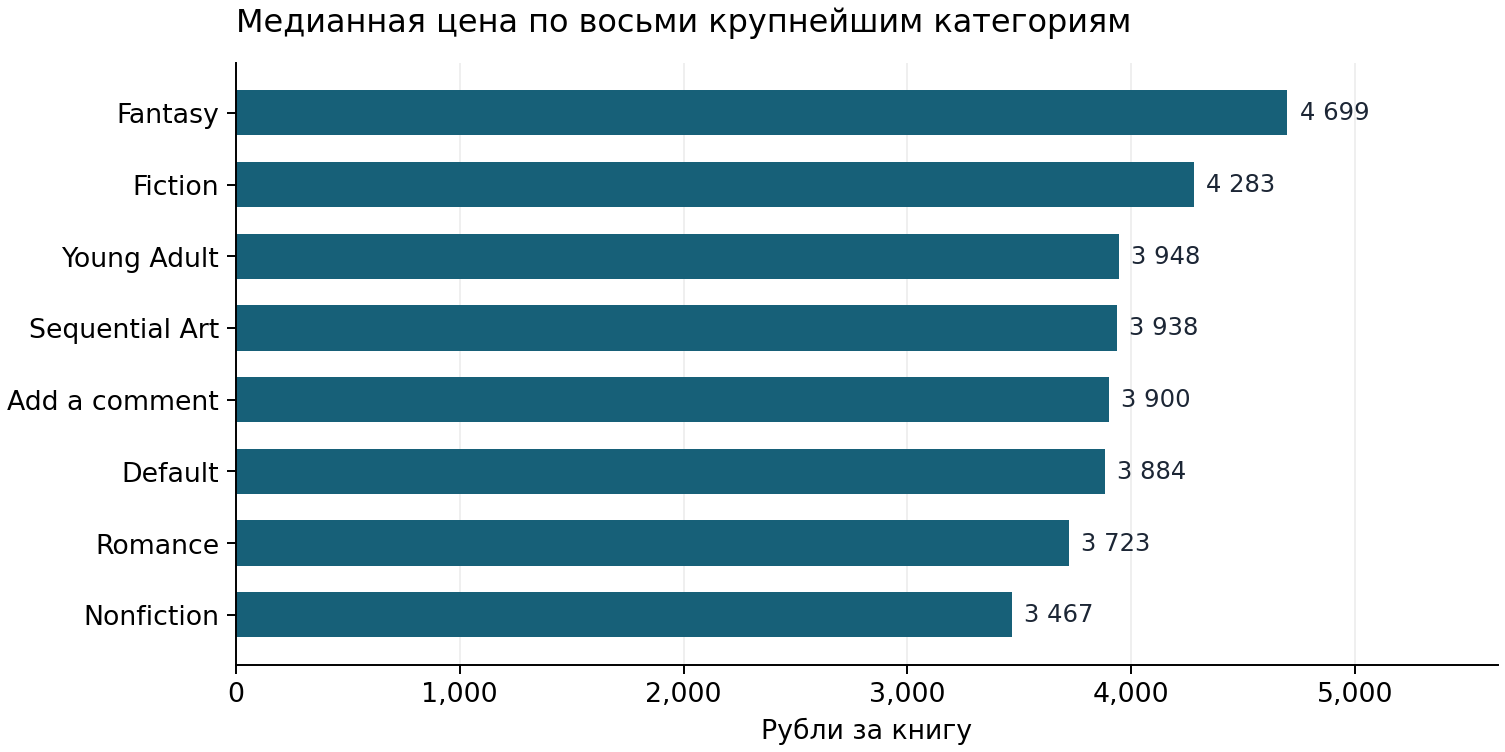

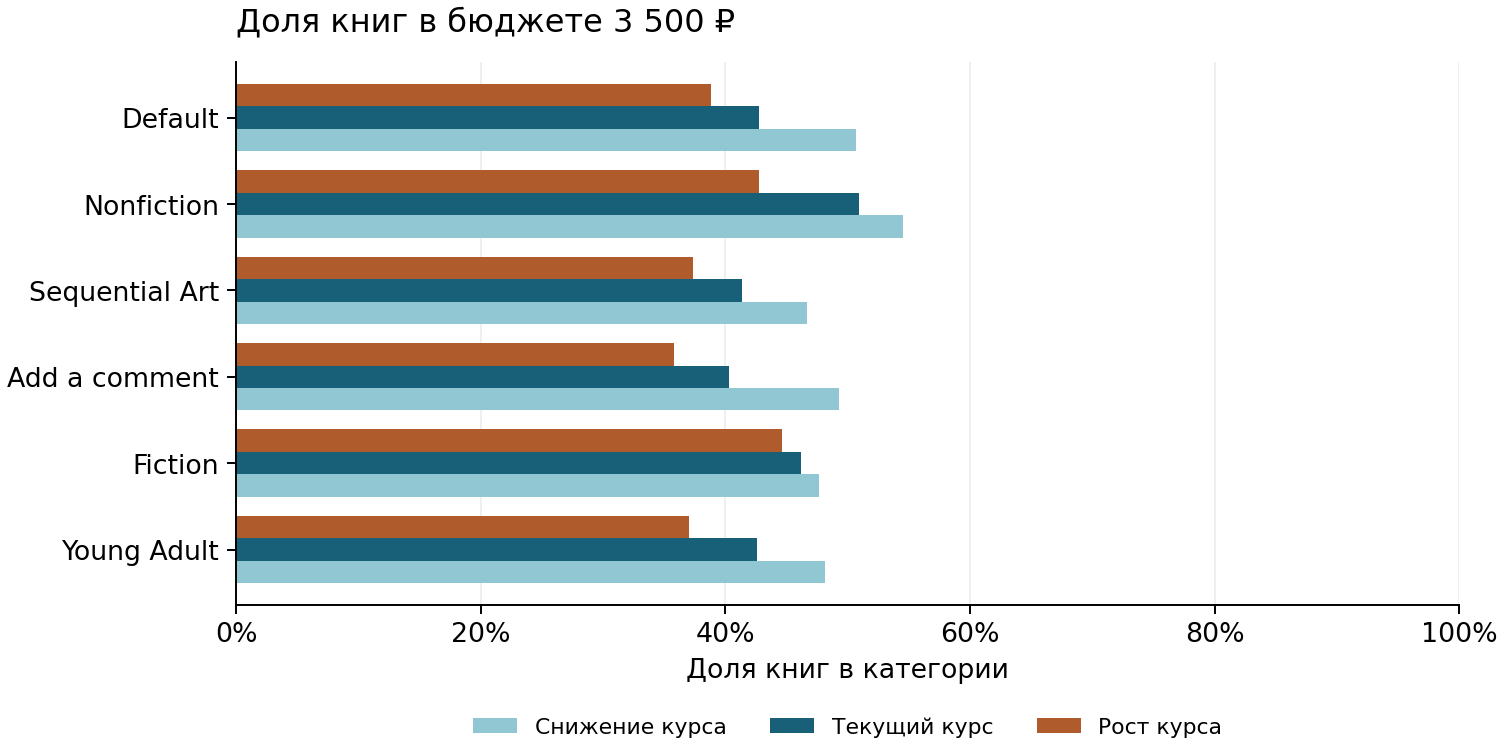

In [5]:

category = pd.read_csv(root / "mart/category_prices.csv")
sensitivity = pd.read_csv(root / "mart/budget_sensitivity.csv")
summary = read_json("mart/analytic_summary.json")
display(category.head(8))
display(pd.DataFrame(summary["scenarios"]).T)
for filename in ("category_prices.png", "budget_sensitivity.png"):
    display(Image(filename=str(root / "mart" / filename), width=800))


## Выводы по сохранённому снимку

1. При курсе 107,8265 ₽ за фунт в бюджет входят 443 из 1 000 книг. По предыдущему курсу 107,7202 ₽ их было бы 444. В обоих расчётах используются те же цены в фунтах.
2. Среди восьми крупнейших категорий медианная цена ниже всего в Nonfiction — около 3 467 ₽. У Fantasy она около 4 699 ₽. В бюджет входят 56 из 110 книг Nonfiction и 17 из 48 книг Fantasy.
3. При снижении курса на 10% в бюджет вошли бы 502 книги, при росте на 10% — 391. Расчёт показывает, как сумма зависит от курса при фиксированных ценах каталога.

Цены и рейтинги на учебном сайте назначены случайно. По этому снимку можно проверить пересчёт цен. Для оценки спроса и изменения магазинных цен понадобились бы другие данные.

## Самопроверка

Проверяются сохранённые результаты. Прогоны с сетью запускаются из терминала по командам в README.

In [6]:

with sqlite3.connect(root / "db/warehouse.db") as db:
    db_ok = db.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
    db_books = db.execute("SELECT count(*) FROM products").fetchone()[0]

calculated = (priced["price_pence"] * priced["rub_x10000"] + 5000) // 10000
from src.observability import alert_report

warning_metrics = {"error_share", "limit_or_block_share", "volume_change", "p95_ms"}
thresholds = config["alerts"]
sample = {metric: thresholds[metric] * 1.1 for metric in warning_metrics if metric in thresholds}
triggered = {row["metric"] for row in alert_report(sample, thresholds) if row["level"] == "warning"}

checks = {
    "Два источника и паспорта": set(config["sources"]) == {"books", "fx"}
        and (root / "docs/source_passports.md").is_file(),
    "Карточки в исходном HTML": diagnostic["needle_in_raw_html"] and not diagnostic["browser_required"],
    "500 или больше чистых книг": len(products) >= 500,
    "Уникальность и связь с курсом": len(priced) == products["business_key"].nunique()
        and priced["rate_date"].notna().all(),
    "Пересчёт до копейки": (calculated == priced["price_rub_kopeks"]).all(),
    "Пересборка из raw без сети": read_json(evidence["offline"])["requests"] == 0,
    "Сохранённая очередь": evidence["resumed_pages"]["repeated"] == 0,
    "БД и три загрузки": db_ok and db_books == len(products)
        and upsert["updated_at_preserved"] and upsert["third"]["products"]["updated"] == 2,
    "Четыре записи отклонены контрактом": len(rejected["rejected"]) == 4,
    "Пороги и запрет записи в mart": len(quality["metrics"]) >= 6
        and read_json(evidence["red_gate"])["mart_unchanged"],
    "Быстрый повтор и 304": saved_runs["repeat"]["codes"].get("304", 0) > 0
        and saved_runs["repeat"]["upsert"]["products"]["updated"] == 0,
    "503 изолирован": saved_runs["fault"]["exit_code"] == 2
        and saved_runs["fault"]["breaker_opened"] == 1,
    "Оповещения": triggered == warning_metrics,
    "n8n принимает оба результата": read_json(evidence["n8n"])["repeat"]["n8n_status"] == "success"
        and read_json(evidence["n8n"])["fault"]["n8n_status"] == "error",
    "Два графика": all((root / "mart" / path).is_file()
        for path in ("category_prices.png", "budget_sensitivity.png")),
    "Схема, data card и правовой чек-лист": all((root / "docs" / path).is_file()
        for path in ("pipeline_diagram.md", "data_card.md", "legal_checklist.md")),
}
display(pd.Series(checks, name="Проверка пройдена").to_frame())
assert all(checks.values())


,Проверка пройдена
Два источника и паспорта,True
Карточки в исходном HTML,True
500 или больше чистых книг,True
Уникальность и связь с курсом,True
Пересчёт до копейки,True
Пересборка из raw без сети,True
Сохранённая очередь,True
БД и три загрузки,True
Четыре записи отклонены контрактом,True
Пороги и запрет записи в mart,True
